In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

# Set seaborn style for better looking charts
sns.set_theme(style="darkgrid")
# Standardize colors so Player 0 is always Blue, Player 1 is Orange, etc.
player_palette = {"Player 0": "blue", "Player 1": "orange", "Player 2": "green", "Player 3": "red"}

def load_replay(filepath):
    print(f"Loading {filepath}...")
    try:
        with open(filepath, 'r', encoding='utf-8') as f:
            html_content = f.read()
        
        raw_tail = html_content.split('window.kaggle = ', 1)[1]
        json_string_candidate = raw_tail.split('window.kaggle.renderer', 1)[0]
        clean_json_string = json_string_candidate.strip().rstrip(';')
        
        data = json.loads(clean_json_string)
        return data['environment']['steps']
        
    except Exception as e:
        print(f"Failed to parse JSON from HTML: {e}")
        return None

# Load the 4-Player Replay
steps = load_replay("../replays/replay_match_2_4-player_seed166982.html")

if steps is not None:
    print(f"Successfully loaded {len(steps)} turns.")



Loading ../replays/replay_match_2_4-player_seed166982.html...
Successfully loaded 228 turns.


In [2]:
# --- DATA EXTRACTION ---
attrition_data = []
deployment_data = []
fleet_launches = []

# Track cumulative production over time for all 4 players
cum_prod = {0: 0, 1: 0, 2: 0, 3: 0}
seen_fleets = set()

for turn_idx, step in enumerate(steps):
    obs = step[0]['observation']
    planets = obs['planets']
    fleets = obs.get('fleets', [])
    
    garrison = {0: 0, 1: 0, 2: 0, 3: 0}
    transit = {0: 0, 1: 0, 2: 0, 3: 0}
    
    # Tally Planet Economy (Garrison & Production)
    for p in planets:
        owner = p[1]
        ships = p[5]
        prod = p[6]
        
        if owner in cum_prod:
            cum_prod[owner] += prod
            garrison[owner] += ships
            
    # Tally Fleet Economy (Transit & New Launches)
    for f in fleets:
        f_id = f[0]
        owner = f[1]
        ships = f[6]
        
        if owner in transit:
            transit[owner] += ships
            
        # Detect new fleet launches
        if f_id not in seen_fleets and owner in [0, 1, 2, 3]:
            seen_fleets.add(f_id)
            fleet_launches.append({
                'Turn': turn_idx,
                'Player': f'Player {owner}',
                'Ships': ships
            })
            
    # Calculate Data per Player for this Turn
    for player_id in range(4):
        alive_ships = garrison[player_id] + transit[player_id]
        
        attrition_data.append({
            'Turn': turn_idx,
            'Player': f'Player {player_id}',
            'Combat_Losses': max(0, cum_prod[player_id] - alive_ships)
        })
        
        deployment_data.append({
            'Turn': turn_idx,
            'Player': f'Player {player_id}',
            'Garrison': garrison[player_id],
            'Transit': transit[player_id],
            'Total': alive_ships
        })



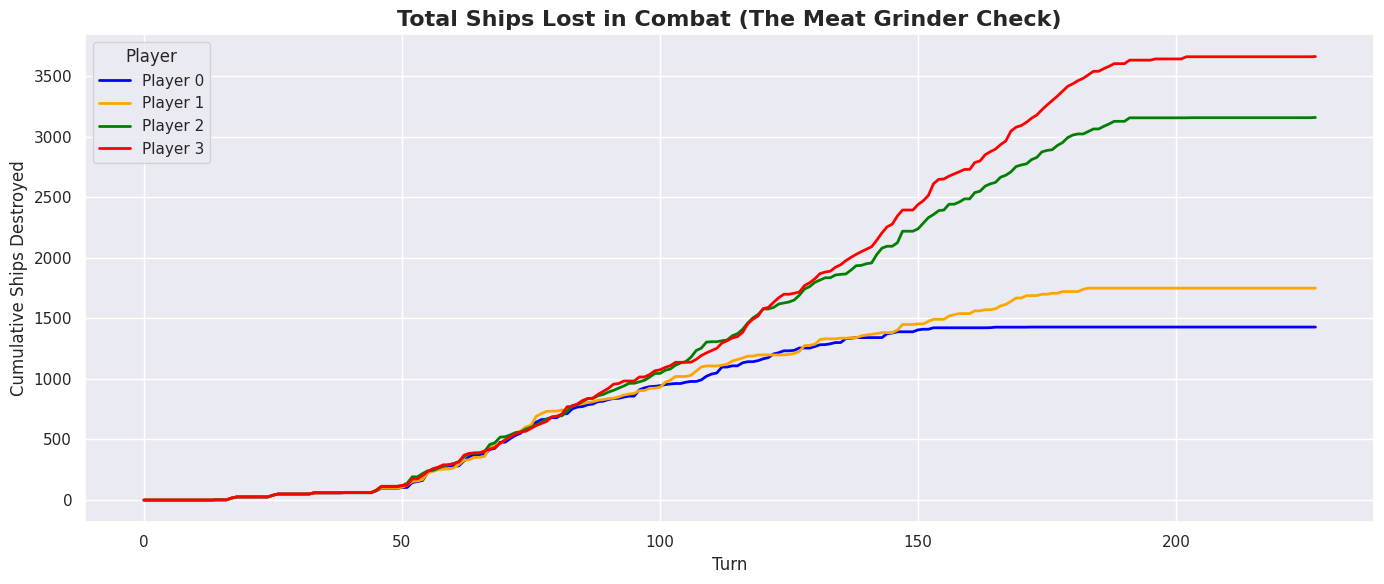

In [3]:
# Create DataFrames
df_attrition = pd.DataFrame(attrition_data)
df_deploy = pd.DataFrame(deployment_data)
df_launches = pd.DataFrame(fleet_launches)

# --- VISUALIZATION 1: THE MEAT GRINDER (ATTRITION) ---
plt.figure(figsize=(14, 6))
sns.lineplot(data=df_attrition, x='Turn', y='Combat_Losses', hue='Player', linewidth=2, palette=player_palette)
plt.title('Total Ships Lost in Combat (The Meat Grinder Check)', fontsize=16, fontweight='bold')
plt.xlabel('Turn', fontsize=12)
plt.ylabel('Cumulative Ships Destroyed', fontsize=12)
plt.tight_layout()
plt.show()



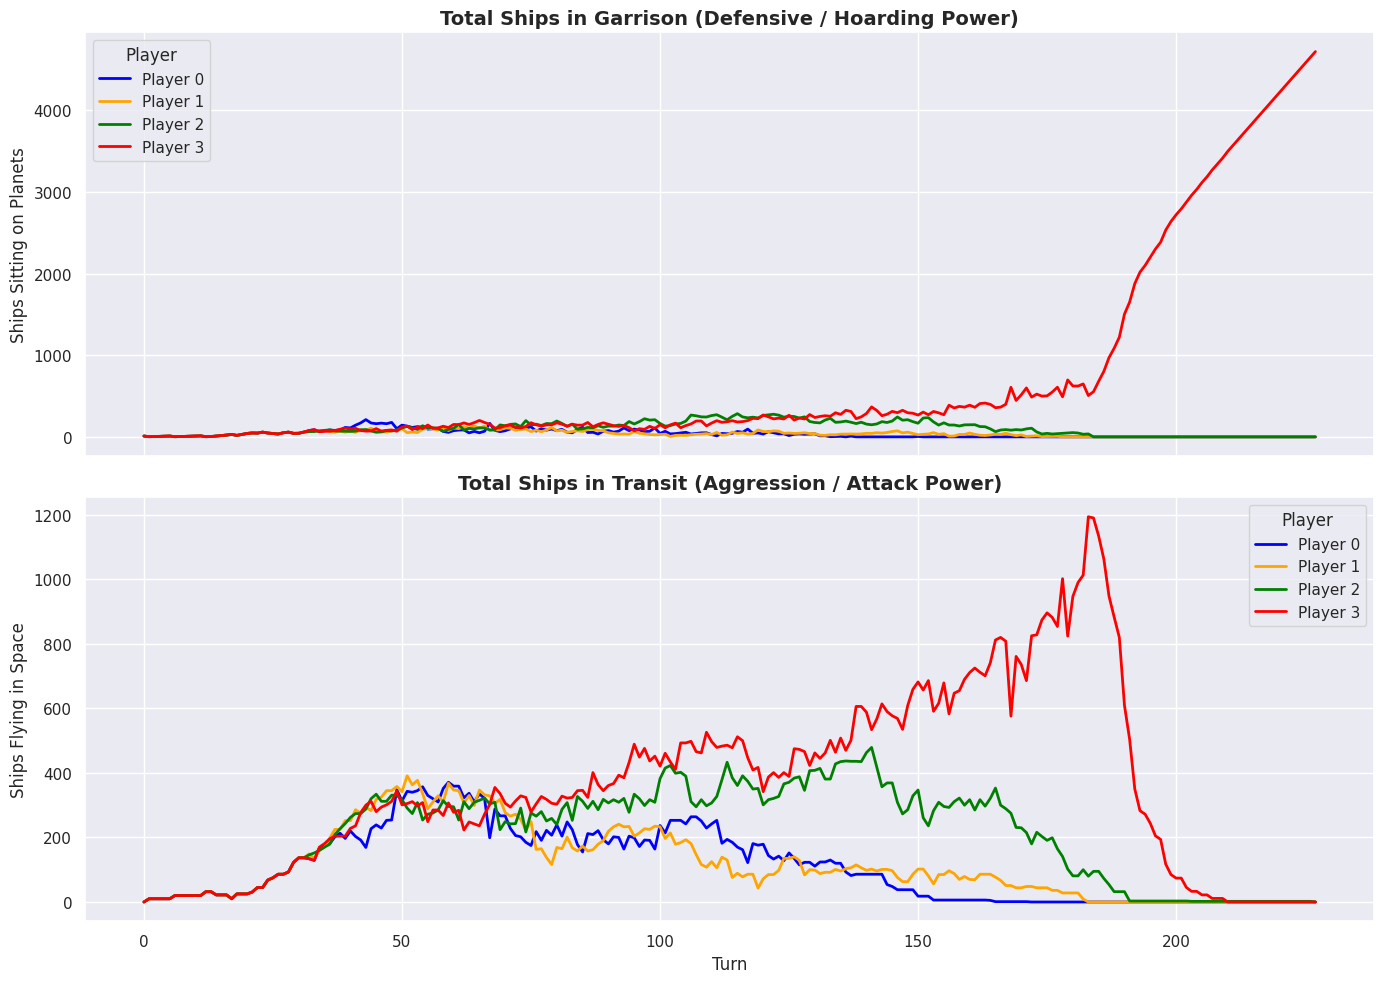

In [4]:
# --- VISUALIZATION 2: THE HOARDING INDEX ---
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

sns.lineplot(data=df_deploy, x='Turn', y='Garrison', hue='Player', ax=axes[0], linewidth=2, palette=player_palette)
axes[0].set_title('Total Ships in Garrison (Defensive / Hoarding Power)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Ships Sitting on Planets')

sns.lineplot(data=df_deploy, x='Turn', y='Transit', hue='Player', ax=axes[1], linewidth=2, palette=player_palette)
axes[1].set_title('Total Ships in Transit (Aggression / Attack Power)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Ships Flying in Space')
axes[1].set_xlabel('Turn', fontsize=12)

plt.tight_layout()
plt.show()



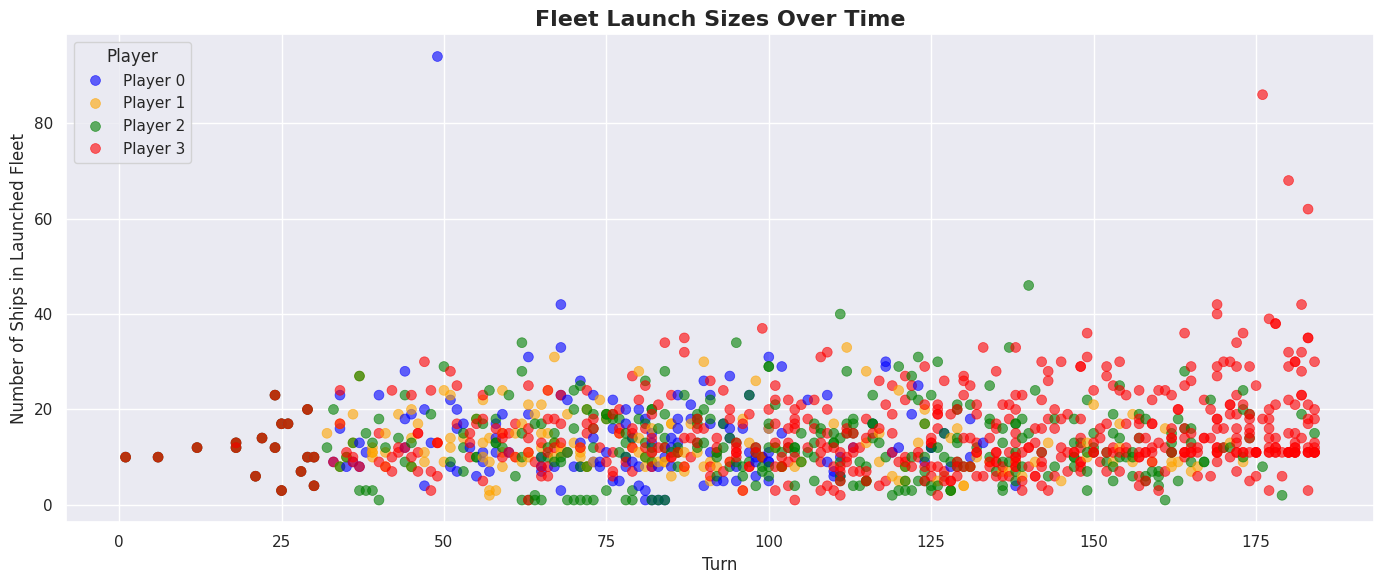

In [5]:
# --- VISUALIZATION 3: LAUNCH SIZES (THE TRICKLE BLEED DETECTOR) ---
if not df_launches.empty:
    plt.figure(figsize=(14, 6))
    sns.scatterplot(data=df_launches, x='Turn', y='Ships', hue='Player', alpha=0.6, s=50, palette=player_palette, edgecolor=None)
    plt.title('Fleet Launch Sizes Over Time', fontsize=16, fontweight='bold')
    plt.xlabel('Turn', fontsize=12)
    plt.ylabel('Number of Ships in Launched Fleet', fontsize=12)
    plt.tight_layout()
    plt.show()